# 01 · Comprensión de los datos

**Proyecto:** SCA-2026-01 · Herramienta de segmentación de clientes de Costanera Andina
**Etapa CRISP-DM y paquetes EDT:** Comprensión de los datos (transversal) · 2.2.1 Extracción, carga y exploración · 2.2.2 Validación del índice de gasto y de la representatividad
**Iteración:** Iteración 1 (13/10 a 28/10) y actualización en la iteración 2 (2.2.3)
**Equipo:** Felipe Ahumada Silva (Jefe de Proyecto) · Francisca Carrasco Lozano (Analista de Datos líder)

**Objetivo de este notebook:** cargar la extracción que entregó Fidelización, medir su calidad, describir las variables y revisar si el índice de gasto y la muestra sirven para segmentar.

**Requerimientos que se trabajan:** RF.1 (carga con resumen), RNF.3 (datos confiables), RNF.14 (representatividad).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from costanera import carga, config, evaluacion, fichas, modelado, preparacion
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
FIG = config.FIGURAS
FIG.mkdir(parents=True, exist_ok=True)

## 1. Carga con resumen (RF.1)
La herramienta informa cuántos registros cargó, cuántos rechazó y por qué. El criterio de aceptación es que el conteo de origen sea igual a cargados más rechazados.

In [2]:
datos, resumen = carga.cargar()
print(resumen.texto())
datos.head()

Registros en el archivo de origen: 200
Registros cargados:                200
Registros rechazados:              0
Duplicados por identificador:      0
Conteo cuadra (origen = cargados + rechazados): sí


,id_cliente,genero,edad,educacion,estado_civil,ingreso_anual_k,indice_gasto
0,1,M,19,High School,Married,15,39
1,2,M,21,Graduate,Single,15,81
2,3,F,20,Graduate,Married,16,6
3,4,F,23,High School,Unknown,16,77
4,5,F,31,Uneducated,Married,17,40


## 2. Diccionario de datos

In [3]:
diccionario = pd.DataFrame({
    "variable": datos.columns,
    "tipo": [str(t) for t in datos.dtypes],
    "descripción": ["Identificador del cliente en el programa de fidelización (se seudonimiza en 2.3.1)",
                    "Género declarado (F/M)", "Edad en años",
                    "Nivel educativo declarado (fuera del alcance del modelo)",
                    "Estado civil declarado (fuera del alcance del modelo)",
                    "Ingreso anual declarado, en miles de dólares",
                    "Índice de gasto de 1 a 100 que asigna el centro comercial"],
    "valores distintos": [datos[c].nunique() for c in datos.columns],
})
diccionario

,variable,tipo,descripción,valores distintos
0,id_cliente,int64,Identificador del cliente en el programa de fi...,200
1,genero,object,Género declarado (F/M),2
2,edad,int64,Edad en años,51
3,educacion,object,Nivel educativo declarado (fuera del alcance d...,7
4,estado_civil,object,Estado civil declarado (fuera del alcance del ...,4
5,ingreso_anual_k,int64,"Ingreso anual declarado, en miles de dólares",64
6,indice_gasto,int64,Índice de gasto de 1 a 100 que asigna el centr...,84


## 3. Calidad de los datos (RNF.3)
Criterio: cero duplicados por identificador y 95 % o más de completitud en las variables usadas.

In [4]:
calidad = pd.DataFrame({
    "completitud_%": (datos.notna().mean() * 100).round(1),
    "faltantes": datos.isna().sum(),
})
print("Duplicados por identificador:", datos["id_cliente"].duplicated().sum())
print("Filas duplicadas exactas:", datos.duplicated().sum())
for col in ["educacion", "estado_civil"]:
    print(f"'Unknown' en {col}: {(datos[col] == 'Unknown').mean():.1%}")
calidad

Duplicados por identificador: 0
Filas duplicadas exactas: 0
'Unknown' en educacion: 13.0%
'Unknown' en estado_civil: 7.5%


,completitud_%,faltantes
id_cliente,100.0,0
genero,100.0,0
edad,100.0,0
educacion,100.0,0
estado_civil,100.0,0
ingreso_anual_k,100.0,0
indice_gasto,100.0,0


,edad,ingreso_anual_k,indice_gasto
count,200.0,200.0,200.0
mean,38.8,60.6,50.2
std,14.0,26.3,25.8
min,18.0,15.0,1.0
25%,28.8,41.5,34.8
50%,36.0,61.5,50.0
75%,49.0,78.0,73.0
max,70.0,137.0,99.0


{'edad': 0, 'ingreso_anual_k': 2, 'indice_gasto': 0}


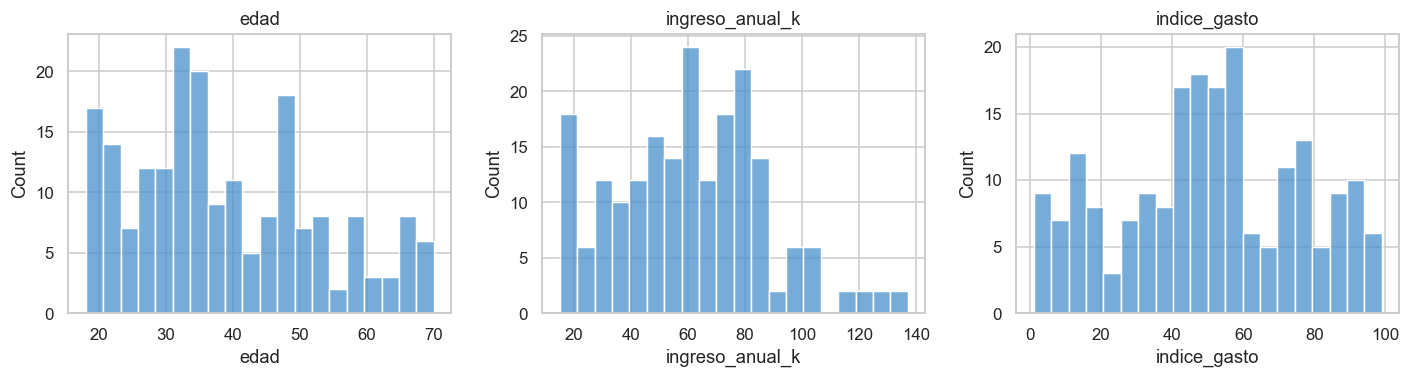

In [5]:
num = ["edad", "ingreso_anual_k", "indice_gasto"]
display(datos[num].describe().round(1))
def atipicos(s):
    q1, q3 = s.quantile([.25, .75]); r = q3 - q1
    return int(((s < q1 - 1.5 * r) | (s > q3 + 1.5 * r)).sum())
print({c: atipicos(datos[c]) for c in num})
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, c in zip(ax, num):
    sns.histplot(datos[c], bins=20, ax=a, color="#4a90cd")
    a.set_title(c)
plt.tight_layout(); plt.savefig(FIG / "01_distribuciones.png", bbox_inches="tight"); plt.show()

Hallazgo: la extracción está completa (100 % en todas las variables), sin duplicados ni valores fuera de rango. Hay **2 valores atípicos de ingreso** (137 k$), que son clientes reales de ingreso alto: se conservan. Educación y estado civil traen categorías `Unknown` (13 % y 7,5 %); no forman parte del alcance del modelo, así que no se usan.

## 4. Representatividad (RNF.14)
Marketing necesita saber qué parte de sus clientes representa la muestra.

genero,F,M,Total
tramo_etario,,,
18-29,29,26,55
30-44,46,30,76
45-59,29,20,49
60+,8,12,20
Total,112,88,200


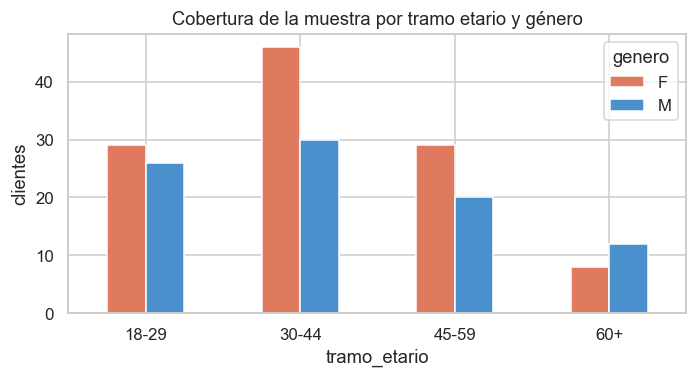

In [6]:
datos["tramo_etario"] = pd.cut(datos["edad"], config.TRAMOS_EDAD, labels=config.ETIQUETAS_TRAMOS)
cobertura = pd.crosstab(datos["tramo_etario"], datos["genero"], margins=True, margins_name="Total")
display(cobertura)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
pd.crosstab(datos["tramo_etario"], datos["genero"]).plot.bar(ax=ax, color=["#e07a5f", "#4a90cd"], rot=0)
ax.set_ylabel("clientes"); ax.set_title("Cobertura de la muestra por tramo etario y género")
plt.tight_layout(); plt.savefig(FIG / "01_cobertura.png", bbox_inches="tight"); plt.show()

Hallazgo: la muestra tiene **200 clientes** (56 % mujeres). El tramo de 60 años o más tiene solo 20 clientes (10 %): cualquier conclusión sobre ese tramo es frágil y se informa a Marketing como limitación.

## 5. Validación del índice de gasto (2.2.2)
El plan supone que el índice de gasto mide el gasto real. El contraste con ventas reales depende de que Administración entregue una muestra de ventas (supuesto del plan). Mientras tanto, se revisa con qué se relaciona el índice.

,edad,ingreso_anual_k,indice_gasto
edad,1.000,-0.012,-0.327
ingreso_anual_k,-0.012,1.000,0.010
indice_gasto,-0.327,0.010,1.000


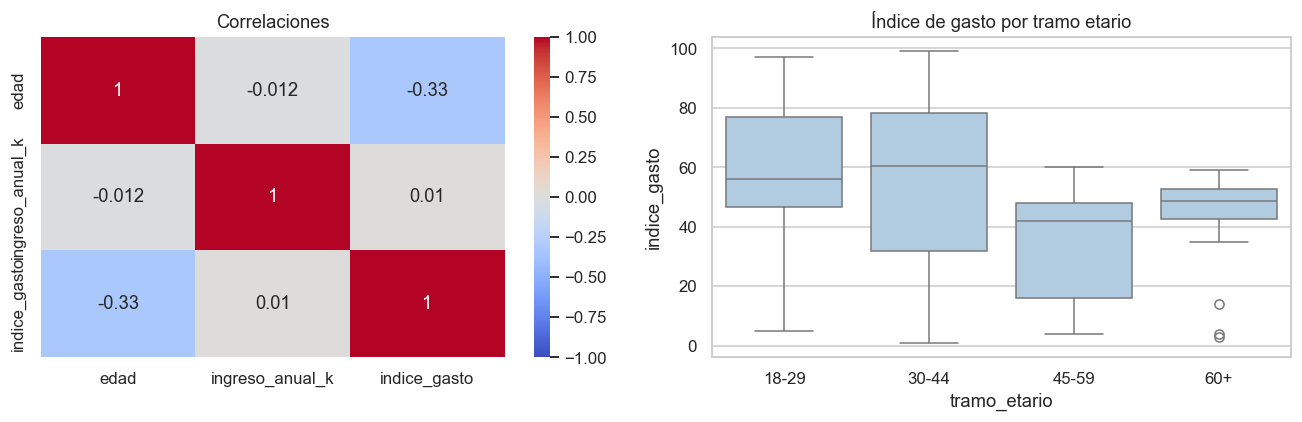

In [7]:
corr = datos[num].corr().round(3)
display(corr)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0]); ax[0].set_title("Correlaciones")
sns.boxplot(data=datos, x="tramo_etario", y="indice_gasto", ax=ax[1], color="#a9cce8")
ax[1].set_title("Índice de gasto por tramo etario")
plt.tight_layout(); plt.savefig(FIG / "01_indice_gasto.png", bbox_inches="tight"); plt.show()

**Hallazgos que cambian el plan:**

1. El índice de gasto **no se relaciona con el ingreso** (r = 0,010): no es un proxy del poder adquisitivo y aporta información propia. Sirve para segmentar.
2. El índice de gasto **baja con la edad** (r = −0,327): los clientes de 45 años o más casi nunca tienen índices altos. Si se segmenta con este índice, los segmentos de gasto alto podrían quedar sin clientes mayores. Esto es el riesgo **R7** del plan (segmentos como sustituto de la edad); se deja como alerta temprana para la evaluación de equidad de la iteración 2.
3. **Desviación D-03:** Administración no entregó las ventas reales en noviembre, como suponía el plan, así que el contraste del índice con ventas queda pendiente. Acción correctiva: se escaló al patrocinador en el comité del 27/11 y se fijó nueva fecha (11/12).

**Decisión para el modelado:** se segmenta con **ingreso anual e índice de gasto**. Edad y género no entran al modelo, para no discriminar por ellos (R7); se usan solo para revisar la composición de cada segmento (RF.6).